In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from pandas import Timedelta
from pandas.tseries import frequencies

from disclose.dataclass.detection_data import DetectionData

### Load data

In [7]:
config_list = [
    {
        "detection_file": Path(r"_static/ELAN_results.csv"),
        "timebin_new": Timedelta("1h"),
        "annotator": "lleboul",
        "filename_format": "%Y_%m_%d_%H_%M_%S_%f%z",
        "recording_file": Path(r"_static\ELAN_recording_periods.csv"),
    },
    {
        "detection_file": Path(r"_static/NEAMS_results.csv"),
        "timebin_new": Timedelta("1h"),
        "annotator": "lleboul",
        "filename_format": "%Y_%m_%d_%H_%M_%S_%f%z",
    },
    {
        "detection_file": Path(r"_static/MADW_results.csv"),
        "timebin_new": Timedelta("1h"),
        "annotator": "lleboul",
        "filename_format": "%Y_%m_%d_%H_%M_%S_%f%z",
    },
]

data_list = DetectionData.from_dict(config_list, merge=False)

for data in data_list:
    data.lat = -49
    data.lon = 70
    data.change_tz("Indian/Kerguelen")

### Overview

In [ ]:
print(data_list[0].overview(annotator="lleboul"))

### Single barplot

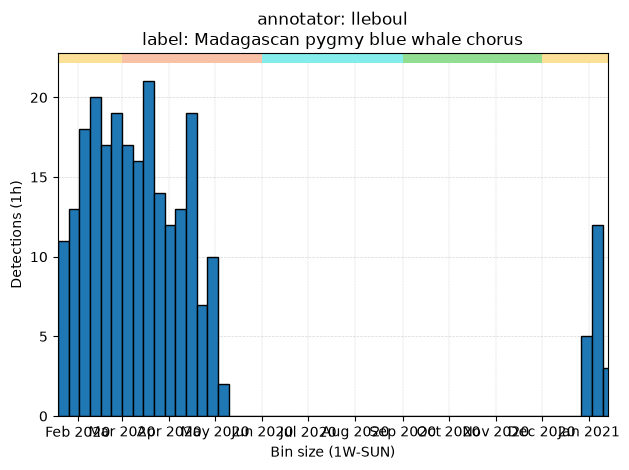

In [4]:
data = data_list[0]
config = config_list[0]

fig, ax = plt.subplots(1, 1)

bin_size = frequencies.to_offset("1W-SUN")
ticks = frequencies.to_offset("1MS")
fmt = "%b %Y"
ax = data.plot.set_ax(ax=ax, x_ticks_res=ticks, date_format=fmt)

data.plot.histogram(
    ax=ax,
    annotator="lleboul",
    label="Madagascan pygmy blue whale chorus",
    bin_size=bin_size,
    effort=True,
    season=True,
)
plt.show()

### Multi-barplot

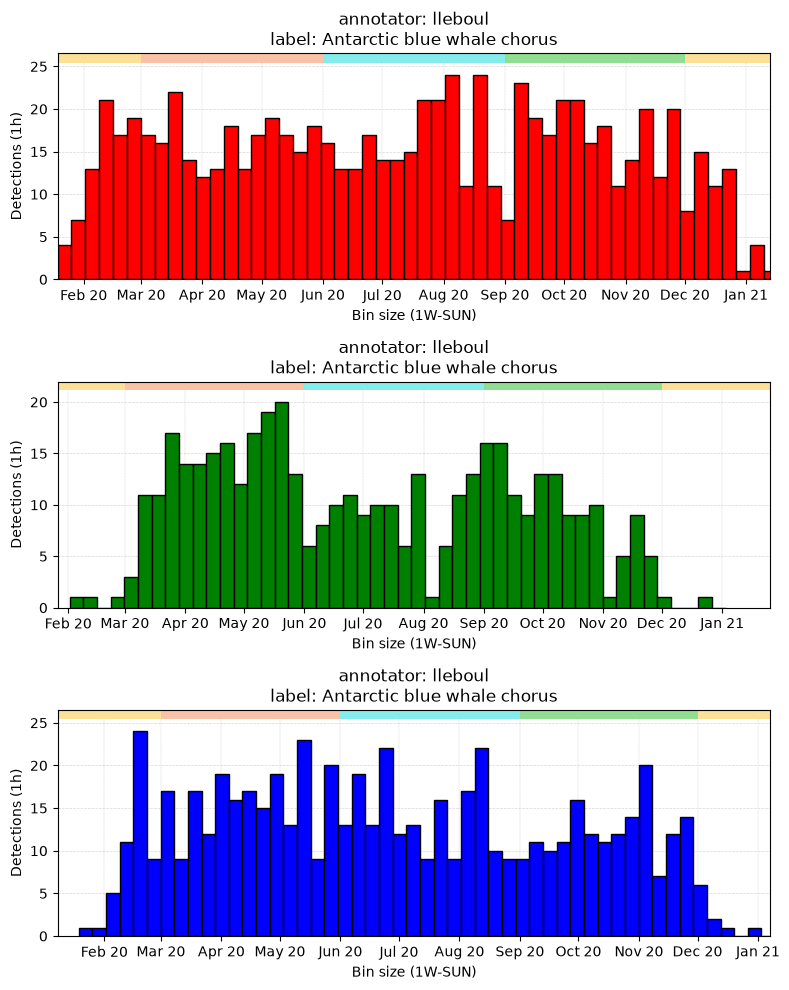

In [16]:
fig, axs = plt.subplots(3, 1, figsize=(8, 10))
colors = ["red", "green", "blue"]

for i in range(len(axs)):
    data = data_list[i]
    axs[i] = data_list[0].plot.set_ax(
        ax=axs[i],
        x_ticks_res=frequencies.to_offset("1MS"),
        date_format="%b %y",
    )
    data.plot.histogram(
        ax=axs[i],
        annotator="lleboul",
        label="Antarctic blue whale chorus",
        bin_size=frequencies.to_offset("1W-SUN"),
        season=True,
        color=colors[i],
    )

plt.show()

### Heatmap plot

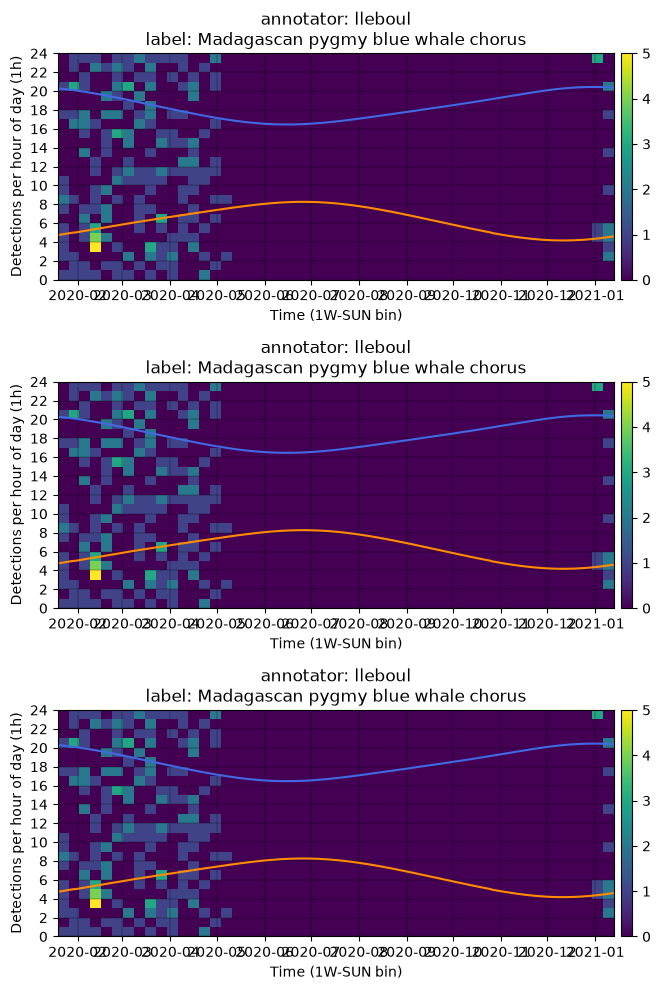

In [27]:
fig, axs = plt.subplots(3, 1, figsize=(8, 10))

for i in range(len(axs)):
    data_list[0].plot.heatmap(
        ax=axs[i],
        annotator="lleboul",
        label="Madagascan pygmy blue whale chorus",
        bin_size=frequencies.to_offset("1W-SUN"),
        show_rise_set=True,
    )
    axs[i].get_legend().remove()
plt.show()

### Scatter plot

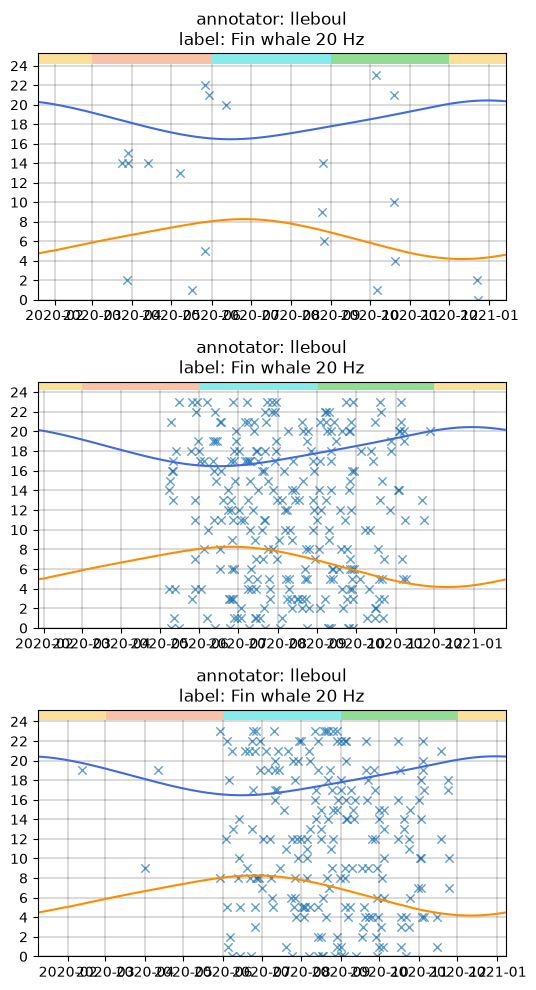

In [29]:
fig, axs = plt.subplots(3, 1, figsize=(8, 10))

for i in range(len(axs)):
    data_list[i].plot.scatter(
        ax=axs[i],
        annotator="lleboul",
        label="Fin whale 20 Hz",
        bin_size=frequencies.to_offset("1W-SUN"),
        show_rise_set=True,
        season=True,
    )
    axs[i].get_legend().remove()
plt.show()